# 10 — From forecast to stocking decision: reorder points and safety stock (Phase 3 · Step 6)

A forecast says *how much demand to expect*. A store manager has to decide *how much stock to hold* — and that depends on how wrong the
forecast tends to be and how much risk of running out is acceptable. This notebook shows how the project's **saved forecasts** and their **saved
forecast errors** turn into a **reorder point** and a **safety stock**, using the `src/inventory` module, and **tests whether the rule delivers
the service level it promises** on days it was not calibrated on.

* **What it is.** A transparent decision-support calculation on the 20 selected items, with every input visible.
* **What it is not.** It is not a claim that the models save money, reduce waste or improve profit. There is no cost model here, and
  lead time, review period and service level are **illustrative inputs**, not facts about any real supplier.
* **Final holdout.** No forecast beyond 2016-04-24 is produced: the reserved days (2016-04-25 → 2016-05-22) are never read. Every example is
  a *past* forecast origin, using only information that was available at that origin.

## 1. Objective

*Given a forecast and the history of how wrong that forecast was, how much stock should cover one replenishment cycle, and does the rule hold its
promise when checked on later data?*

Concretely, the notebook (1) builds a reorder point for each selected item and model, (2) explains each ingredient, (3) compares the empirical
method with the textbook normal-distribution formula **without using the latter**, (4) backtests the rule — calibrate on earlier folds, test on a later fold —
and (5) shows how sensitive the result is to lead time and service level.

## 2. Method — the ideas, in plain language

**Lead time** is the number of days between placing an order and receiving it. **Review period** is the number of days between two opportunities to
place an order (0 = you can order any day, "continuous review"). Whatever stock you hold must last through the **protection interval** =
`lead time + review period`, because an order placed today only helps after the lead time, and a missed ordering day delays the next chance by a review period.

* **Expected demand** over the protection interval = the sum of the forecast for those days.
* **Forecast error over the interval** = actual total demand − forecast total. Positive means demand was higher than forecast (a shortfall if you stocked only the forecast).
* **Safety stock** = extra stock held to cover those shortfalls. It is the *empirical quantile* of the saved interval-sized errors at the chosen service level:
  if the 95 % quantile of past errors is 6 units, then holding the forecast + 6 units would have covered 95 % of the past intervals.
* **Reorder point** = expected demand + safety stock. When the *inventory position* (stock on hand + stock on order) falls to the reorder point, order.
* **Order-up-to level** (periodic review) — the same number, used as the level the position is topped back up to at each review.

**Cycle service level vs fill rate.** The service level used here is the probability that demand in one replenishment cycle does *not* exceed the stock held for it
(*no stock-out in the cycle*). The **fill rate** is the share of all demanded *units* delivered from stock. They are different numbers: a 95 % cycle service level can
mean a stock-out in 1 cycle out of 20 — whether it was a shortage of 1 unit or 50 units, the cycle counts equally, and fill rate would not.

**Why empirical errors and not a formula.** The textbook safety stock `z × σ_daily × √(lead time)` assumes daily errors are independent and bell-shaped. Phase 2's residual diagnostics found
autocorrelated residuals for the aggregate classical models, the errors of intermittent demand are skewed (many near-zero days, occasional spikes), and errors summed over overlapping windows are
dependent by construction. So the quantile is read directly from errors computed
over **every** run of `protection_days` consecutive forecast days inside each fold — overlapping windows are kept, preserving the dependence between neighbouring days.
(Because those windows overlap, their number is *not* an independent sample size; the notebook says so wherever it matters.)

**Forecast vs decision.** The same forecast can lead to different decisions: a higher service level, a longer lead time or a noisier model all raise the safety stock without changing the forecast at all.

**Honest limits of this calculation.** Lot sizes, minimum order quantities, price breaks, shelf life, substitution, lost-sales cost and holding cost are not modelled. Forecast errors are taken as
stationary within the saved history. The supported protection interval is at most 28 days, the length of the saved forecasts.

## 3. Setup and reproducibility

Run from the project root with `python -m jupyter nbconvert --to notebook --execute --inplace notebooks/10_inventory_decision_support.ipynb` (under a minute). The notebook only
**reads** saved forecast files (written by notebooks 04–06) and writes small files to `artifacts/inventory/` and figures to `reports/phase3/`.

In [1]:
import sys
from pathlib import Path


def _find_project_root(start: Path) -> Path:
    """Walk up from `start` until a directory containing config.yaml is found."""
    for candidate in [start, *start.parents]:
        if (candidate / "config.yaml").exists():
            return candidate
    raise FileNotFoundError(
        f"Could not find config.yaml in any parent directory of '{start}'. Run this notebook from within the project."
    )


PROJECT_ROOT = _find_project_root(Path.cwd())
sys.path.insert(0, str(PROJECT_ROOT))

import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.evaluation.forecast_artifacts import (
    audit_forecast_table,
    forecasts_dir,
    load_item_forecast_tables,
    load_selected_item_series,
    notebook_command,
)
from src.inventory import (
    ASSUMPTIONS_TEXT,
    InventoryAssumptions,
    assumptions_from_config,
    bootstrap_safety_stock_interval,
    cumulative_error_samples,
    explain_result,
    reorder_point_at_origin,
    safety_stock_from_errors,
    service_level_backtest,
    summarize_service_level_backtest,
)
from src.utils.config import load_config
from src.utils.provenance import build_run_metadata, write_json

warnings.filterwarnings("ignore")
logging.getLogger().setLevel(logging.WARNING)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})

config = load_config()
p2, p3, inv = config["phase2"], config["phase3"], config["inventory"]
inventory_dir = PROJECT_ROOT / p3["inventory_dir"]
reports_dir = PROJECT_ROOT / config["reports"]["phase3_dir"]
for directory in (inventory_dir, reports_dir):
    directory.mkdir(parents=True, exist_ok=True)


def save_figure(fig, filename):
    fig.savefig(reports_dir / filename, dpi=150, bbox_inches="tight")


print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__)

Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3


## 4. The inputs: saved forecasts and illustrative assumptions

Forecasts are **read from saved files** — nothing is re-fitted here. Each table is audited (same folds, actuals equal to the development series, finite and non-negative forecasts, nothing after 2016-04-24).

In [2]:
files = {"Phase 2 item-level": p2["item_level_long_results_filename"], "Phase 3 XGBoost": p3["xgboost_long_results_filename"]}
tables, problems = load_item_forecast_tables(list(files.values()), config)
for label, name in files.items():
    if name in problems:
        print(f"MISSING {label}: {problems[name]}")

series = load_selected_item_series(config)
index = next(iter(series.values())).index
frames = []
for label, name in files.items():
    if name not in tables:
        continue
    checks = audit_forecast_table(tables[name], kind="item", item_series=series, dev_dates=index)
    status = "all checks pass" if all(c.passed for c in checks) else "FAILED: " + "; ".join(c.name for c in checks if not c.passed)
    print(f"{label:20s} {name}: {len(tables[name])} rows, models {sorted(tables[name]['model'].unique())} -> {status}")
    assert all(c.passed for c in checks), f"{name} failed its integrity audit"
    frames.append(tables[name])
if not frames:
    raise FileNotFoundError("No saved item-level forecast table found. Create one with: " + notebook_command("04_classical_models"))

forecast_table = pd.concat(frames, ignore_index=True)
PREFERRED = ["SeasonalNaive", "Croston(alpha=0.1)", "TSB(alpha=0.1,beta=0.1)", "XGBoost(pooled)"]
models = [m for m in PREFERRED if m in set(forecast_table["model"])]
print("\nModels used (all saved, none re-fitted):", models)
class_of = forecast_table.drop_duplicates("item_id").set_index("item_id")["demand_class"].to_dict()
items = sorted(class_of, key=lambda i: (["Smooth", "Intermittent", "Erratic", "Lumpy"].index(class_of[i]), i))
print(f"{len(items)} items; folds {sorted(forecast_table['fold'].unique())}; last forecast date {pd.to_datetime(forecast_table['date']).max().date()}")

Phase 2 item-level   item_level_backtest_long.csv: 8400 rows, models ['Croston(alpha=0.1)', 'SeasonalNaive', 'TSB(alpha=0.1,beta=0.1)'] -> all checks pass


Phase 3 XGBoost      xgboost_item_level_backtest_long.csv: 11200 rows, models ['XGBoost(per-item)', 'XGBoost(pooled)', 'XGBoost(pooled,no-events)', 'XGBoost(pooled,poisson)'] -> all checks pass

Models used (all saved, none re-fitted): ['SeasonalNaive', 'Croston(alpha=0.1)', 'TSB(alpha=0.1,beta=0.1)', 'XGBoost(pooled)']
20 items; folds [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]; last forecast date 2016-04-24


In [3]:
assumptions = assumptions_from_config(config)
print("ILLUSTRATIVE assumptions (from config.yaml `inventory:`; change them there or in the cells below):")
print(f"  lead time          : {assumptions.lead_time_days} days")
print(f"  review period      : {assumptions.review_period_days} days (0 = continuous review)")
print(f"  protection interval: {assumptions.protection_days} days")
print(f"  target cycle service level: {assumptions.service_level:.0%}")
print("\n" + ASSUMPTIONS_TEXT)
PROTECTION = assumptions.protection_days
SERVICE = assumptions.service_level

ILLUSTRATIVE assumptions (from config.yaml `inventory:`; change them there or in the cells below):
  lead time          : 7 days
  review period      : 0 days (0 = continuous review)
  protection interval: 7 days
  target cycle service level: 95%

Lead time, review period, service level and stock on hand are user-supplied or illustrative inputs, not facts about any real supplier. No cost, holding or shortage-penalty model is used, so no savings are claimed.


## 5. One worked example, step by step

The most recent development fold (fold 5, forecast window 2016-03-28 → 2016-04-24) is treated as "today". The reorder point is built from that fold's **saved forecast** and from errors in **folds 1–4 only**.
The demand that actually happened in fold 5 is shown afterwards, for comparison — it was not known at the order time and is never used to calculate the stock.

In [4]:
example_model = "TSB(alpha=0.1,beta=0.1)" if "TSB(alpha=0.1,beta=0.1)" in models else models[0]
example_item = next(i for i in items if class_of[i] == "Intermittent")
result, context = reorder_point_at_origin(forecast_table, model=example_model, item_id=example_item, fold=5, assumptions=assumptions)

print(f"Item {example_item} ({class_of[example_item]}), model {example_model}, order time = start of fold 5 ({context['forecast_start']})")
print(f"Forecast for the {PROTECTION} protection days: {np.round(context['forecast_values'][:PROTECTION], 3).tolist()}")
print(f"Calibration: {result.n_error_samples} cumulative {PROTECTION}-day errors from folds {context['calibration_folds']} (overlapping windows, not independent)")
print()
print(explain_result(result, assumptions, item_label=example_item))
print(f"\nFor comparison only (not known at the order time): demand actually realised over those {PROTECTION} days = {context['realised_demand_over_protection']:.0f} units; "
      f"reorder point was {result.reorder_point:.2f} -> {'covered' if context['realised_demand_over_protection'] <= result.reorder_point else 'NOT covered (a stock-out in this cycle)'}.")

Item FOODS_3_042 (Intermittent), model TSB(alpha=0.1,beta=0.1), order time = start of fold 5 (2016-03-28)
Forecast for the 7 protection days: [2.069, 2.069, 2.069, 2.069, 2.069, 2.069, 2.069]
Calibration: 88 cumulative 7-day errors from folds [1, 2, 3, 4] (overlapping windows, not independent)

Protection interval for FOODS_3_042: 7 day(s) (lead time 7 + review period 0).
Expected demand over it (from the forecast): 14.5 units.
Safety stock (the 95% quantile of 88 saved cumulative forecast errors, floored at 0): 10.7 units.
Reorder point = expected demand + safety stock = 25.2 units.

A forecast is an estimate of demand; a stocking decision also needs the forecast's typical error and an acceptable risk of running out. The reorder point below = expected demand over the protection interval (from the forecast) + safety stock (from the saved forecast errors at the chosen service level).
The service level used here is a cycle service level: the target probability that demand during one repl

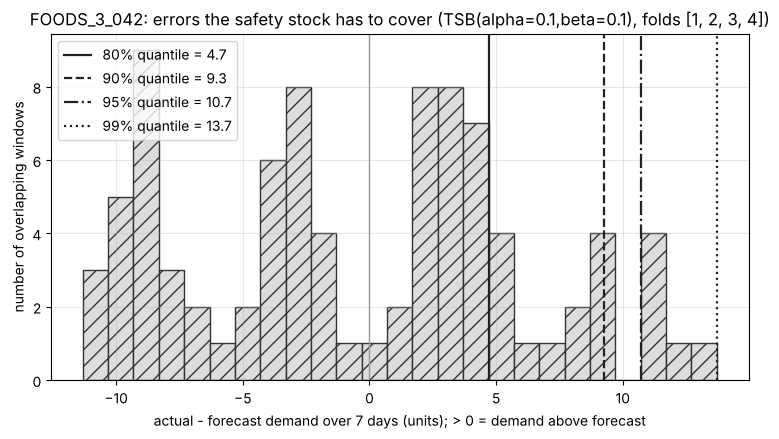

The vertical lines are the safety stock at each service level: the higher the promise, the further into the tail the stock has to reach.


In [5]:
errors = cumulative_error_samples(forecast_table, PROTECTION, model=example_model, item_id=example_item, folds=context["calibration_folds"])
levels = [0.80, 0.90, 0.95, 0.99]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(errors, bins=min(25, max(8, len(np.unique(errors)))), color="#DDDDDD", edgecolor="#333333", hatch="//")
styles = ["-", "--", "-.", ":"]
for level, style in zip(levels, styles):
    value = safety_stock_from_errors(errors, level)
    ax.axvline(value, color="#222222", linestyle=style, linewidth=1.6, label=f"{level:.0%} quantile = {value:.1f}")
ax.axvline(0, color="#999999", linewidth=1)
ax.set_xlabel(f"actual - forecast demand over {PROTECTION} days (units); > 0 = demand above forecast")
ax.set_ylabel("number of overlapping windows")
ax.set_title(f"{example_item}: errors the safety stock has to cover ({example_model}, folds {context['calibration_folds']})")
ax.legend()
save_figure(fig, p3["inventory_worked_example_plot_filename"])
plt.show()
print("The vertical lines are the safety stock at each service level: the higher the promise, the further into the tail the stock has to reach.")

## 6. Reorder points for every selected item

For each item and model: the order is placed at the start of fold 5, calibrated on folds 1–4. `SS interval` is the 90 % percentile interval of the safety stock when the saved errors are resampled in blocks (a seeded block bootstrap that respects the overlap of the windows); it
describes sampling noise in the error history only. The last two columns repeat the "for comparison only" check — a single cycle, so it says very little on its own (Section 8 does this properly).

In [6]:
rows = []
for item in items:
    for model in models:
        try:
            res, ctx = reorder_point_at_origin(forecast_table, model=model, item_id=item, fold=5, assumptions=assumptions,
                                               min_error_windows_warning=int(inv["min_error_windows_warning"]))
        except ValueError as exc:
            rows.append({"item_id": item, "demand_class": class_of[item], "model": model, "status": str(exc)})
            continue
        errs = cumulative_error_samples(forecast_table, PROTECTION, model=model, item_id=item, folds=ctx["calibration_folds"])
        low, high = bootstrap_safety_stock_interval(errs, SERVICE, n_resamples=int(inv["bootstrap_resamples"]),
                                                    seed=int(inv["bootstrap_seed"]), block_size=PROTECTION)
        rows.append({
            "item_id": item, "demand_class": class_of[item], "model": model, "status": "ok", "order_time": ctx["forecast_start"],
            "protection_days": res.protection_days, "service_level": res.service_level, "expected_demand": res.expected_demand,
            "safety_stock": res.safety_stock, "reorder_point": res.reorder_point, "safety_stock_ci_low": low, "safety_stock_ci_high": high,
            "n_error_samples": res.n_error_samples, "realised_demand_same_days": ctx["realised_demand_over_protection"],
            "covered_in_this_cycle": bool(ctx["realised_demand_over_protection"] <= res.reorder_point),
            "warnings": " | ".join(res.warnings),
        })
demo = pd.DataFrame(rows)
demo.to_csv(inventory_dir / p3["inventory_demo_filename"], index=False, lineterminator="\n")
print(f"{len(demo)} (item, model) reorder points saved to artifacts/inventory/{p3['inventory_demo_filename']}")

view = demo[demo["status"] == "ok"].copy()
view["SS interval"] = view.apply(lambda r: f"[{r.safety_stock_ci_low:.1f}, {r.safety_stock_ci_high:.1f}]", axis=1)
short = {m: m.split("(")[0] for m in models}
wide = view.assign(model=view["model"].map(short)).pivot_table(
    index=["demand_class", "item_id"], columns="model", values=["expected_demand", "safety_stock", "reorder_point"], observed=True)
wide.columns = [f"{a.replace('expected_demand', 'expected').replace('safety_stock', 'SS').replace('reorder_point', 'ROP')} {b}" for a, b in wide.columns]
order = {c: i for i, c in enumerate(["Smooth", "Intermittent", "Erratic", "Lumpy"])}
wide = wide.sort_index(key=lambda idx: idx.map(order) if idx.name == "demand_class" else idx)
display(wide.round(2))
print("Units: units of the item over the protection interval. Every number is for an ILLUSTRATIVE lead time and service level.")

80 (item, model) reorder points saved to artifacts/inventory/inventory_demo_reorder_points.csv


expected Croston  expected SeasonalNaive  expected TSB  expected XGBoost  ROP Croston  ROP SeasonalNaive  ROP TSB  ROP XGBoost  SS Croston  SS SeasonalNaive  SS TSB  SS XGBoost
demand_class item_id                                                                                                                                                                                      
Smooth       FOODS_3_067             13.07                    14.0         13.65             13.81        19.69               23.0    20.31        19.18        6.63               9.0    6.66        5.38
             FOODS_3_230             32.12                    35.0         32.13             32.72        62.09               64.0    61.98        55.88       29.98              29.0   29.85       23.15
             FOODS_3_263             50.76                    55.0         51.07             51.41        78.92               79.0    74.19        68.83       28.16              24.0   23.12       17.42
             FOODS_3_330             28.04                    25.0         28.35             27.62        38.67               37.0    38.53        35.55       10.63              12.0   10.19        7.92
             FOODS_3_348             50.96                    46.0         51.04             47.80        63.69               63.0    63.65        65.76       12.73              17.0   12.61       17.95
Intermittent FOODS_3_042             14.32                    19.0         14.49             20.80        23.85               35.0    25.20        26.47        9.53              16.0   10.71        5.67
             FOODS_3_206              7.86                     0.0          0.00              0.38        13.04                1.0     4.20         0.38        5.18               1.0    4.20        0.00
             FOODS_3_264              3.68                     7.0          5.32              3.70        11.24               14.0    10.59        10.65        7.57               7.0    5.26        6.94
             FOODS_3_341              4.57                     4.0          3.96              2.98         8.06                7.0     7.17         7.38        3.50               3.0    3.21        4.40
             FOODS_3_780              5.93                     7.0          6.78              5.39        11.67               12.0    12.23        15.14        5.74               5.0    5.46        9.75
Erratic      FOODS_3_076             23.10                    25.0         23.25             25.37        34.50               38.0    34.50        34.54       11.39              13.0   11.26        9.16
             FOODS_3_313             34.32                    32.0         34.32             34.31        41.03               41.0    41.02        40.71        6.71               9.0    6.69        6.40
             FOODS_3_319             72.35                    86.0         72.43             69.25       131.19              109.0   115.45        78.87       58.84              23.0   43.02        9.62
             FOODS_3_404             61.09                    55.0         61.22             65.60       103.71               78.0    80.39        80.06       42.62              23.0   19.17       14.46
             FOODS_3_702             58.36                    73.0         58.70             56.56        93.29              129.0   107.32        98.67       34.93              56.0   48.61       42.10
Lumpy        FOODS_3_024             18.19                    14.0         18.47             26.36        40.14               22.0    32.81        32.97       21.95               8.0   14.34        6.61
             FOODS_3_271             18.47                     0.0          3.11              1.07        24.18                7.0     8.62         8.89        5.70               7.0    5.51        7.82
             FOODS_3_422              8.49                     8.0          9.05              9.87        26.65               27.0    28.05        28.66       18.16     

Units: units of the item over the protection interval. Every number is for an ILLUSTRATIVE lead time and service level.


### 6.1 Forecast vs decision: the same item, different models

Two models can disagree about expected demand *and* about how much risk there is around it. The reorder point combines both, so the model with the lower forecast is not automatically the one with the lower reorder point.

In [7]:
compare = view[view["item_id"] == example_item][["model", "expected_demand", "safety_stock", "reorder_point", "n_error_samples"]].set_index("model")
display(compare.round(2))
share = (view["safety_stock"] / view["reorder_point"].replace(0, np.nan)).groupby(view["demand_class"]).median().reindex(["Smooth", "Intermittent", "Erratic", "Lumpy"])
print("Median share of the reorder point that is safety stock, by class (all models):")
print(share.round(2).to_string())

,expected_demand,safety_stock,reorder_point,n_error_samples
model,,,,
SeasonalNaive,19.00,16.00,35.00,88
Croston(alpha=0.1),14.32,9.53,23.85,88
"TSB(alpha=0.1,beta=0.1)",14.49,10.71,25.20,88
XGBoost(pooled),20.80,5.67,26.47,88


Median share of the reorder point that is safety stock, by class (all models):
demand_class
Smooth          0.31
Intermittent    0.45
Erratic         0.31
Lumpy           0.62


## 7. Why not the normal formula? An explicit comparison (the formula is NOT used)

For each item and model, the textbook value `z × σ × √L` — with `σ` the standard deviation of the **daily** errors in folds 1–4 and `z` the normal quantile of the service level — is placed next to the empirical safety stock.
If daily errors were independent and bell-shaped the two would agree; the size and direction of the gap shows how far the real errors are from that picture.

In [8]:
from statistics import NormalDist

z = NormalDist().inv_cdf(SERVICE)
gap_rows = []
for item in items:
    for model in models:
        daily = cumulative_error_samples(forecast_table, 1, model=model, item_id=item, folds=[1, 2, 3, 4])
        if len(daily) < 2:
            continue
        normal_ss = max(0.0, z * float(np.std(daily, ddof=1)) * np.sqrt(assumptions.protection_days))
        empirical = float(demo[(demo["item_id"] == item) & (demo["model"] == model)]["safety_stock"].iloc[0])
        gap_rows.append({"item_id": item, "demand_class": class_of[item], "model": model, "empirical_SS": empirical, "normal_formula_SS": normal_ss,
                         "empirical_minus_normal": empirical - normal_ss})
gaps = pd.DataFrame(gap_rows)
summary_gap = gaps.groupby("demand_class").agg(
    items_x_models=("item_id", "size"),
    empirical_larger=("empirical_minus_normal", lambda s: int((s > 0.5).sum())),
    normal_larger=("empirical_minus_normal", lambda s: int((s < -0.5).sum())),
    median_difference=("empirical_minus_normal", "median"),
).reindex(["Smooth", "Intermittent", "Erratic", "Lumpy"])
display(summary_gap.round(2))
print(f"'larger' = by more than 0.5 units. z = {z:.3f} for a {SERVICE:.0%} service level. Neither column is a correct answer; the point is that the formula's assumptions (independent, symmetric daily errors) do not hold here, so the saved errors are read directly.")

# autocorrelation of the daily errors, the main reason for the empirical approach
lag1 = []
for item in items:
    for model in models:
        daily = cumulative_error_samples(forecast_table, 1, model=model, item_id=item, folds=[1, 2, 3, 4])
        if len(daily) > 3 and np.std(daily) > 0:
            lag1.append(float(np.corrcoef(daily[:-1], daily[1:])[0, 1]))
print(f"Lag-1 autocorrelation of daily errors: median {np.median(lag1):.2f}; {np.mean(np.array(lag1) > 0.2):.0%} of (item, model) series exceed 0.20 (independent errors would give about 0).")

,items_x_models,empirical_larger,normal_larger,median_difference
demand_class,,,,
Smooth,20,9,8,0.13
Intermittent,20,12,6,0.61
Erratic,20,9,9,0.13
Lumpy,20,14,5,4.02


'larger' = by more than 0.5 units. z = 1.645 for a 95% service level. Neither column is a correct answer; the point is that the formula's assumptions (independent, symmetric daily errors) do not hold here, so the saved errors are read directly.


Lag-1 autocorrelation of daily errors: median 0.12; 39% of (item, model) series exceed 0.20 (independent errors would give about 0).


## 8. Does the rule keep its promise? A backtest on later folds

For each item, model and test fold `k` with at least two earlier folds (so k = 3, 4, 5), the safety stock is calibrated on folds `< k` only and then applied to **every** `protection_days`-day window of fold `k`:
a window is a stock-out if its actual demand exceeds the saved forecast for the same days plus the safety stock. The **achieved cycle service level** is the share of windows without a stock-out; it is compared with the **target**. Intervals come
from a seeded bootstrap that resamples whole (item, fold) cells, because windows inside a cell overlap.

In [9]:
TARGETS = (0.80, 0.90, 0.95, 0.99)
cell_frames = []
for model in models:
    cells = service_level_backtest(forecast_table, PROTECTION, TARGETS, model=model)
    cell_frames.append(cells)
backtest = pd.concat(cell_frames, ignore_index=True)
backtest.to_csv(inventory_dir / p3["inventory_backtest_filename"], index=False, lineterminator="\n")

summary_rows = []
for model in models:
    part = backtest[backtest["model"] == model]
    s = summarize_service_level_backtest(part, n_resamples=int(inv["bootstrap_resamples"]), seed=int(inv["bootstrap_seed"]),
                                         min_cells_warning=int(inv["min_error_windows_warning"]))
    s.insert(0, "model", model)
    summary_rows.append(s)
backtest_summary = pd.concat(summary_rows, ignore_index=True)
backtest_summary.to_csv(inventory_dir / p3["inventory_backtest_summary_filename"], index=False, lineterminator="\n")

n_ok = int((backtest["status"] == "ok").sum())
print(f"{len(backtest)} cells ({n_ok} evaluated, {len(backtest) - n_ok} skipped: not enough earlier folds or a failed fold) -> artifacts/inventory/{p3['inventory_backtest_filename']}")
display(backtest_summary.round(3).set_index(["model", "target_cycle_service"])[["n_cells", "n_windows", "achieved_cycle_service", "ci_low", "ci_high", "gap", "note"]])
print("gap = achieved - target (negative = the rule fell short of its promise). Windows overlap and cells are 28-day slices of the same 20 items, so these intervals are indicative, not a formal calibration test.")

1600 cells (960 evaluated, 640 skipped: not enough earlier folds or a failed fold) -> artifacts/inventory/inventory_service_level_backtest.csv


n_cells  n_windows  achieved_cycle_service  ci_low  ci_high    gap note
model                   target_cycle_service                                                                         
SeasonalNaive           0.80                       60       1320                   0.714   0.642    0.781 -0.086     
                        0.90                       60       1320                   0.826   0.763    0.885 -0.074     
                        0.95                       60       1320                   0.877   0.824    0.923 -0.073     
                        0.99                       60       1320                   0.915   0.864    0.956 -0.075     
Croston(alpha=0.1)      0.80                       60       1320                   0.717   0.651    0.781 -0.083     
                        0.90                       60       1320                   0.836   0.789    0.883 -0.064     
                        0.95                       60       1320                   0.889   0.848    0.926 -0.061     
                        0.99                       60       1320                   0.929   0.890    0.961 -0.061     
TSB(alpha=0.1,beta=0.1) 0.80                       60       1320                   0.702   0.636    0.768 -0.098     
                        0.90                       60       1320                   0.833   0.786    0.880 -0.067     
                        0.95                       60       1320                   0.892   0.846    0.933 -0.058     
                        0.99                       60       1320                   0.924   0.881    0.960 -0.066     
XGBoost(pooled)         0.80                       60       1320                   0.745   0.693    0.798 -0.055     
                        0.90                       60       1320                   0.848   0.805    0.890 -0.052     
                        0.95                       60       1320                   0.898   0.859    0.935 -0.052     
                        0.99                       60       1320                   0.932   0.892    0.967 -0.058

gap = achieved - target (negative = the rule fell short of its promise). Windows overlap and cells are 28-day slices of the same 20 items, so these intervals are indicative, not a formal calibration test.


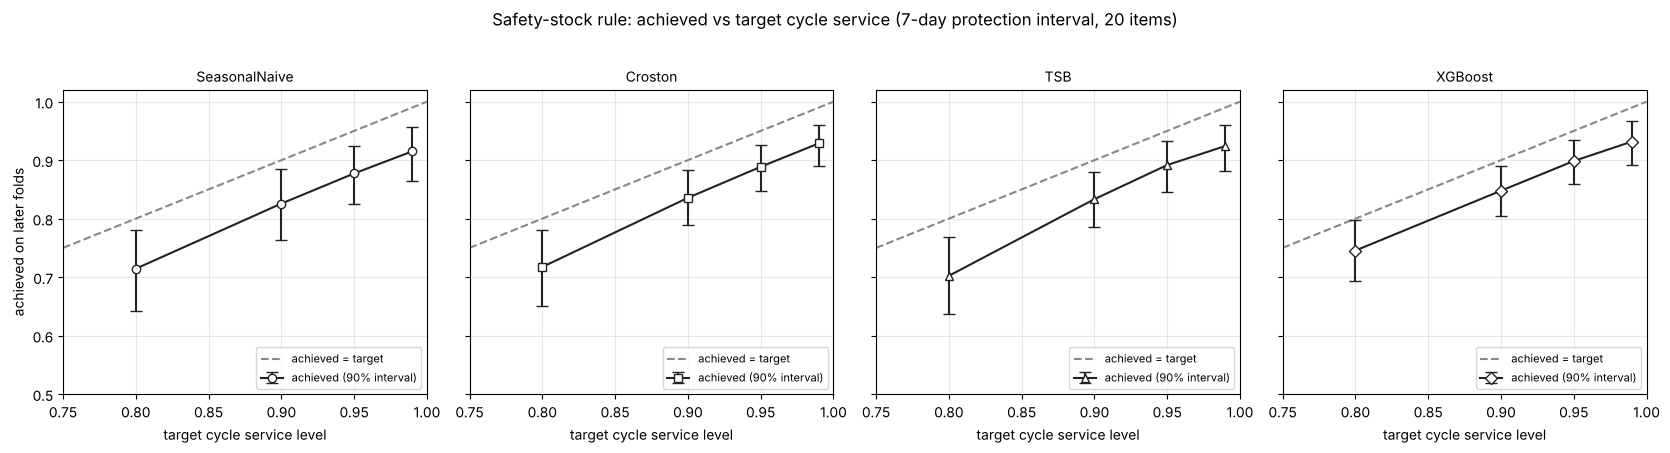

In [10]:
fig, axes = plt.subplots(1, len(models), figsize=(4.2 * len(models), 4.4), sharey=True, squeeze=False)
markers = ["o", "s", "^", "D"]
for ax, model, marker in zip(axes[0], models, markers):
    part = backtest_summary[backtest_summary["model"] == model].sort_values("target_cycle_service")
    ax.plot([0.75, 1.0], [0.75, 1.0], color="#888888", linestyle="--", label="achieved = target")
    ax.errorbar(part["target_cycle_service"], part["achieved_cycle_service"],
                yerr=[part["achieved_cycle_service"] - part["ci_low"], part["ci_high"] - part["achieved_cycle_service"]],
                fmt=marker + "-", color="#222222", markerfacecolor="white", capsize=4, label="achieved (90% interval)")
    ax.set_title(short[model], fontsize=10)
    ax.set_xlabel("target cycle service level")
    ax.set_xlim(0.75, 1.0)
    ax.set_ylim(0.5, 1.02)
    ax.legend(fontsize=8, loc="lower right")
axes[0][0].set_ylabel("achieved on later folds")
fig.suptitle(f"Safety-stock rule: achieved vs target cycle service ({PROTECTION}-day protection interval, 20 items)", y=1.02)
fig.tight_layout()
save_figure(fig, p3["inventory_plot_filename"])
plt.show()

### 8.1 By demand class

The same backtest, pooled by the items' Phase 1 demand class (for one target level).

In [11]:
class_rows = []
for model in models:
    part = backtest[(backtest["model"] == model) & (backtest["status"] == "ok") & (np.isclose(backtest["target_cycle_service"], SERVICE))]
    part = part.assign(demand_class=part["item_id"].map(class_of))
    for label, grp in part.groupby("demand_class"):
        class_rows.append({"model": short[model], "demand_class": label, "cells": len(grp), "windows": int(grp["n_test_windows"].sum()),
                           "achieved": 1 - grp["n_stockout_windows"].sum() / grp["n_test_windows"].sum(), "target": SERVICE})
by_class = pd.DataFrame(class_rows)
by_class["gap"] = by_class["achieved"] - by_class["target"]
by_class["_r"] = by_class["demand_class"].map(order)
display(by_class.sort_values(["_r", "model"]).drop(columns="_r").round(3).set_index(["demand_class", "model"]))

cells  windows  achieved  target    gap
demand_class model                                                 
Smooth       Croston           15      330     0.824    0.95 -0.126
             SeasonalNaive     15      330     0.773    0.95 -0.177
             TSB               15      330     0.827    0.95 -0.123
             XGBoost           15      330     0.867    0.95 -0.083
Intermittent Croston           15      330     0.897    0.95 -0.053
             SeasonalNaive     15      330     0.894    0.95 -0.056
             TSB               15      330     0.873    0.95 -0.077
             XGBoost           15      330     0.867    0.95 -0.083
Erratic      Croston           15      330     0.952    0.95  0.002
             SeasonalNaive     15      330     0.930    0.95 -0.020
             TSB               15      330     0.955    0.95  0.005
             XGBoost           15      330     0.952    0.95  0.002
Lumpy        Croston           15      330     0.882    0.95 -0.068
             SeasonalNaive     15      330     0.912    0.95 -0.038
             TSB               15      330     0.912    0.95 -0.038
             XGBoost           15      330     0.909    0.95 -0.041

### 8.2 By test fold, and an arithmetic sanity check

If the rule falls short of its target, is that a bug in the arithmetic or a failure to generalise to later data? Two checks: (a) the achieved level for each test fold separately; (b) the **same** quantile rule evaluated **in-sample** (each item's safety stock computed from the very windows it is scored on). In-sample, the "higher" empirical quantile
covers at least the target share by construction, so any shortfall in 8 is a *generalisation* gap (later folds differ from earlier ones, and a few earlier folds give a short, noisy error history), not a calculation error.

In [12]:
fold_rows = []
for model in models:
    part = backtest[(backtest["model"] == model) & (backtest["status"] == "ok") & (np.isclose(backtest["target_cycle_service"], SERVICE))]
    for fold, grp in part.groupby("fold"):
        fold_rows.append({"model": short[model], "test_fold": int(fold), "windows": int(grp["n_test_windows"].sum()),
                          "achieved": 1 - grp["n_stockout_windows"].sum() / grp["n_test_windows"].sum()})
by_fold = pd.DataFrame(fold_rows).pivot(index="model", columns="test_fold", values="achieved")
by_fold.columns = [f"test fold {c} (calibrated on folds 1-{c - 1})" for c in by_fold.columns]
display(by_fold.round(3))

insample = []
for model in models:
    covered = windows_n = 0
    for item in items:
        e = cumulative_error_samples(forecast_table, PROTECTION, model=model, item_id=item)
        ss = safety_stock_from_errors(e, SERVICE)
        covered += int((e <= ss).sum())
        windows_n += len(e)
    insample.append({"model": short[model], "in-sample coverage": covered / windows_n, "target": SERVICE})
sanity = pd.DataFrame(insample).set_index("model")
display(sanity.round(3))
assert (sanity["in-sample coverage"] >= SERVICE - 1e-12).all(), "in-sample coverage must reach the target by construction"
print("In-sample coverage reaches the target for every model (as it must), so the shortfall on later folds is a generalisation gap, not an arithmetic error.")

,test fold 3 (calibrated on folds 1-2),test fold 4 (calibrated on folds 1-3),test fold 5 (calibrated on folds 1-4)
model,,,
Croston,0.841,0.925,0.900
SeasonalNaive,0.823,0.898,0.911
TSB,0.843,0.925,0.907
XGBoost,0.866,0.916,0.914


,in-sample coverage,target
model,,
SeasonalNaive,0.963,0.95
Croston,0.958,0.95
TSB,0.958,0.95
XGBoost,0.955,0.95


In-sample coverage reaches the target for every model (as it must), so the shortfall on later folds is a generalisation gap, not an arithmetic error.


## 9. Sensitivity: how much do the illustrative inputs matter?

The example item and model of Section 5, at the same order time, with the lead time and the target service level varied one at a time. The forecast does not change; only the decision inputs do.

expected_demand  safety_stock  reorder_point
varied               value                                              
lead time (days)     3.00              6.21          6.26          12.47
                     7.00             14.49         10.71          25.20
                     14.00            28.97         15.43          44.40
                     21.00            43.46         20.14          63.60
service level        0.80             14.49          4.71          19.20
                     0.90             14.49          9.28          23.76
                     0.95             14.49         10.71          25.20
                     0.99             14.49         13.71          28.20
review period (days) 0.00             14.49         10.71          25.20
                     7.00             28.97         15.43          44.40

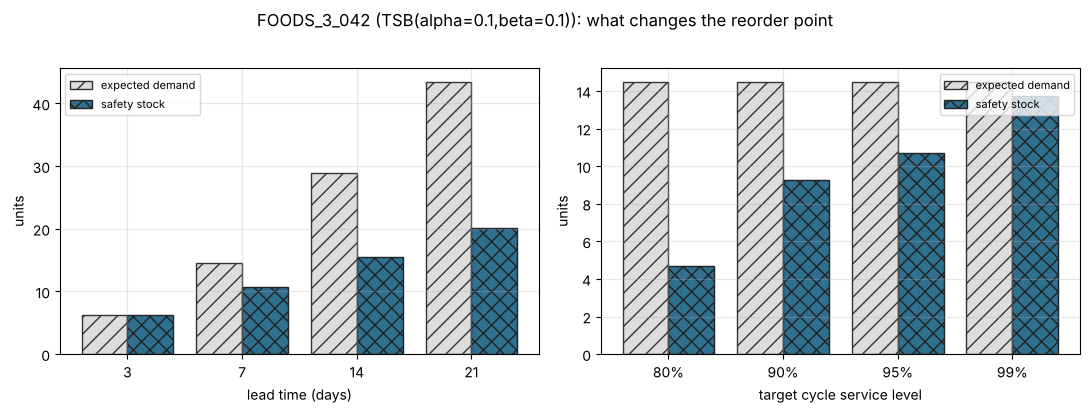

In [13]:
sens_rows = []
for lead in (3, 7, 14, 21):
    a = InventoryAssumptions(lead_time_days=lead, review_period_days=assumptions.review_period_days, service_level=SERVICE)
    r, _ = reorder_point_at_origin(forecast_table, model=example_model, item_id=example_item, fold=5, assumptions=a)
    sens_rows.append({"varied": "lead time (days)", "value": lead, "expected_demand": r.expected_demand, "safety_stock": r.safety_stock, "reorder_point": r.reorder_point})
for level in (0.80, 0.90, 0.95, 0.99):
    a = InventoryAssumptions(lead_time_days=assumptions.lead_time_days, review_period_days=assumptions.review_period_days, service_level=level)
    r, _ = reorder_point_at_origin(forecast_table, model=example_model, item_id=example_item, fold=5, assumptions=a)
    sens_rows.append({"varied": "service level", "value": level, "expected_demand": r.expected_demand, "safety_stock": r.safety_stock, "reorder_point": r.reorder_point})
for review in (0, 7):
    a = InventoryAssumptions(lead_time_days=assumptions.lead_time_days, review_period_days=review, service_level=SERVICE)
    r, _ = reorder_point_at_origin(forecast_table, model=example_model, item_id=example_item, fold=5, assumptions=a)
    sens_rows.append({"varied": "review period (days)", "value": review, "expected_demand": r.expected_demand, "safety_stock": r.safety_stock, "reorder_point": r.reorder_point})
sensitivity = pd.DataFrame(sens_rows)
sensitivity.to_csv(inventory_dir / p3["inventory_sensitivity_filename"], index=False, lineterminator="\n")
display(sensitivity.round(2).set_index(["varied", "value"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, key, xlabel in zip(axes, ["lead time (days)", "service level"], ["lead time (days)", "target cycle service level"]):
    part = sensitivity[sensitivity["varied"] == key]
    ax.bar(np.arange(len(part)) - 0.2, part["expected_demand"], width=0.4, color="#DDDDDD", edgecolor="#333333", hatch="//", label="expected demand")
    ax.bar(np.arange(len(part)) + 0.2, part["safety_stock"], width=0.4, color="#2F6F8F", edgecolor="#222222", hatch="xx", label="safety stock")
    ax.set_xticks(np.arange(len(part)))
    ax.set_xticklabels([f"{v:.0%}" if key == "service level" else str(int(v)) for v in part["value"]])
    ax.set_xlabel(xlabel)
    ax.set_ylabel("units")
    ax.legend(fontsize=8)
fig.suptitle(f"{example_item} ({example_model}): what changes the reorder point", y=1.02)
fig.tight_layout()
save_figure(fig, p3["inventory_sensitivity_plot_filename"])
plt.show()

## 10. Results — interpretation (computed from the tables above)

In [14]:
lines = []
ok_demo = demo[demo["status"] == "ok"]
lines.append(f"Reorder points were computed for {ok_demo['item_id'].nunique()} items x {ok_demo['model'].nunique()} models at the start of fold 5, with an illustrative {assumptions.lead_time_days}-day lead time, "
             f"{assumptions.review_period_days}-day review period and {SERVICE:.0%} target cycle service level.")
share_ss = float((ok_demo["safety_stock"] / ok_demo["reorder_point"].replace(0, np.nan)).median())
lines.append(f"Safety stock is a median {share_ss:.0%} of the reorder point; by class: " + ", ".join(f"{k} {v:.0%}" for k, v in share.items()) + " (median over items and models).")
for model in models:
    row = backtest_summary[(backtest_summary["model"] == model) & (np.isclose(backtest_summary["target_cycle_service"], SERVICE))]
    if row.empty:
        continue
    r = row.iloc[0]
    verdict = "below" if r["achieved_cycle_service"] < SERVICE - 0.02 else ("above" if r["achieved_cycle_service"] > SERVICE + 0.02 else "close to")
    lines.append(f"{short[model]}: at a {SERVICE:.0%} target the achieved cycle service on later folds was {r['achieved_cycle_service']:.1%} "
                 f"(90% interval {r['ci_low']:.1%}-{r['ci_high']:.1%}; {int(r['n_cells'])} cells, {int(r['n_windows'])} overlapping windows) - {verdict} the target.")
shortfalls = backtest_summary[backtest_summary["gap"] < -0.02]
lines.append(f"In {len(shortfalls)} of {len(backtest_summary)} (model, target) combinations the achieved level fell short of the target by more than 2 percentage points; "
             f"in {int((backtest_summary['gap'] > 0.02).sum())} it exceeded the target by more than 2 points.")
worst_fold = by_fold.min(axis=1)
lines.append(f"Daily forecast errors have a median lag-1 correlation of {np.median(lag1):.2f} ({np.mean(np.array(lag1) > 0.2):.0%} of series above 0.20); errors summed over overlapping windows are dependent by construction, and intermittent-demand errors are skewed, so the empirical quantile of interval-sized errors is used rather than a formula that assumes independent, symmetric errors.")
lines.append("In-sample the same rule reaches its target by construction (Section 8.2), so any shortfall on later folds is a generalisation gap: later windows were not like the earlier ones the stock was calibrated on. The reasons were not isolated in this notebook; plausible ones are a short, noisy error history (88 overlapping windows from four folds at most, fewer for earlier test folds) and changes in demand level between folds.")
for line in lines:
    print("-", line)

- Reorder points were computed for 20 items x 4 models at the start of fold 5, with an illustrative 7-day lead time, 0-day review period and 95% target cycle service level.
- Safety stock is a median 42% of the reorder point; by class: Smooth 31%, Intermittent 45%, Erratic 31%, Lumpy 62% (median over items and models).
- SeasonalNaive: at a 95% target the achieved cycle service on later folds was 87.7% (90% interval 82.4%-92.3%; 60 cells, 1320 overlapping windows) - below the target.
- Croston: at a 95% target the achieved cycle service on later folds was 88.9% (90% interval 84.8%-92.6%; 60 cells, 1320 overlapping windows) - below the target.
- TSB: at a 95% target the achieved cycle service on later folds was 89.2% (90% interval 84.6%-93.3%; 60 cells, 1320 overlapping windows) - below the target.
- XGBoost: at a 95% target the achieved cycle service on later folds was 89.8% (90% interval 85.9%-93.5%; 60 cells, 1320 overlapping windows) - below the target.
- In 16 of 16 (model, target)

## 11. Limitations

* **Illustrative inputs.** Lead time, review period and service level are examples. A real decision uses the real supplier's lead time (itself uncertain), the business's cost of a stock-out against the cost of holding stock, and shelf-life.
* **No cost or savings model.** The notebook computes stock levels and whether they would have covered past demand; it says nothing about money, waste or profit, and nothing here should be read as a saving.
* **Twenty items, one store, five 28-day folds.** The backtest cells are few, the windows inside them overlap, and later folds contain different seasons from earlier ones. The intervals are indicative, not a formal calibration test.
* **Stationarity assumption.** Safety stock assumes the next cycle's errors resemble the saved ones. A change in demand level (a new competitor, a promotion, a stock-out in the history that hid real demand) breaks that.
* **Censored demand.** Sales are not demand: on days a product was out of stock the recorded sales understate what customers wanted, and the errors computed from them inherit that bias.
* **The forecast is the one issued at the fold origin.** In the backtest the expected demand of a window is the saved forecast for those days; a live system would re-forecast at each order time, and the results could differ.
* **Cycle service level is not fill rate.** A target of 95 % cycles without a stock-out does not mean 95 % of units are delivered.
* **Protection interval at most 28 days.** Longer lead times are refused rather than extrapolated.
* **No live forecasts, final holdout untouched.** No forecast after 2016-04-24 is produced and the reserved 28 days are not evaluated.

## 12. Conclusion

In [15]:
metadata = build_run_metadata(
    "inventory", config=config, config_keys=["inventory", "backtest"],
    extra={
        "models": models, "items": len(items), "protection_days": PROTECTION, "service_level": SERVICE,
        "targets": list(TARGETS), "backtest_cells": int(len(backtest)), "backtest_cells_evaluated": n_ok,
        "assumptions": "illustrative; no cost or savings model",
    },
)
write_json(inventory_dir / p3["inventory_metadata_filename"], metadata)

print("What was done: reorder points and safety stocks from SAVED forecasts and SAVED forecast errors, with a backtest of the rule on later folds.")
print("What the backtest showed:")
for line in lines[2:]:
    print(" -", line)
print("\nWhat it does not show: any cost, waste or profit effect; behaviour on other stores, items, seasons or the final holdout.")
print("Status: development folds only; illustrative assumptions; no savings claimed; final holdout (2016-04-25 to 2016-05-22) not used.")
print(f"Saved to artifacts/inventory/: {p3['inventory_demo_filename']}, {p3['inventory_backtest_filename']}, {p3['inventory_backtest_summary_filename']}, {p3['inventory_sensitivity_filename']}, {p3['inventory_metadata_filename']}; 3 figures in reports/phase3/.")

What was done: reorder points and safety stocks from SAVED forecasts and SAVED forecast errors, with a backtest of the rule on later folds.
What the backtest showed:
 - SeasonalNaive: at a 95% target the achieved cycle service on later folds was 87.7% (90% interval 82.4%-92.3%; 60 cells, 1320 overlapping windows) - below the target.
 - Croston: at a 95% target the achieved cycle service on later folds was 88.9% (90% interval 84.8%-92.6%; 60 cells, 1320 overlapping windows) - below the target.
 - TSB: at a 95% target the achieved cycle service on later folds was 89.2% (90% interval 84.6%-93.3%; 60 cells, 1320 overlapping windows) - below the target.
 - XGBoost: at a 95% target the achieved cycle service on later folds was 89.8% (90% interval 85.9%-93.5%; 60 cells, 1320 overlapping windows) - below the target.
 - In 16 of 16 (model, target) combinations the achieved level fell short of the target by more than 2 percentage points; in 0 it exceeded the target by more than 2 points.
 - Dail

### How to reproduce

```powershell
python -m pytest tests/inventory                      # unit tests of the inventory layer
python -m jupyter nbconvert --to notebook --execute --inplace notebooks/10_inventory_decision_support.ipynb
```

The logic is in `src/inventory/reorder.py` (public API in `src/inventory/__init__.py`); the illustrative defaults are in `config.yaml` (`inventory:`).